<a href="https://colab.research.google.com/github/abhi-7-7/Flight_Delay_Prediction/blob/main/Notebooks/Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Flight Delay Prediction — Preprocessing Notebook (CSV Loading Fix)

This version prioritizes the original `flights.csv` on disk over a potentially filtered `raw` variable left in memory. It adds month coverage diagnostics and fits destination grouping from the actual training split. Run from a restarted runtime and verify all audit outputs before trusting results.


## Cell 1 — Imports and reproducibility

Run this first. Keep the random seed fixed for repeatability.

In [ ]:
import os, json, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
print("Imports ready")

Imports ready


## Cell 2 — Load `flights.csv`

If you are appending this to `01_eda.ipynb`, it will reuse the existing `raw` variable. In a fresh Colab notebook, it asks you to upload `flights.csv`.

In [ ]:
# Always prefer the original CSV on disk to avoid accidentally reusing a filtered/stale `raw` from EDA.
csv_candidates = ["/content/flights.csv", "flights.csv"]
csv_path = next((p for p in csv_candidates if os.path.isfile(p)), None)
if csv_path is not None:
    raw = pd.read_csv(csv_path)
    print(f"Loaded original CSV: {csv_path}")
elif "raw" in globals() and isinstance(raw, pd.DataFrame):
    # Fallback only when the CSV is unavailable. Verify its row count/date coverage below.
    raw = raw.copy()
    print("WARNING: CSV not found; reusing existing raw DataFrame. Verify it is the complete original dataset.")
else:
    raise FileNotFoundError("flights.csv not found in /content or current directory.")

print("Raw shape:", raw.shape)
if {"year", "month", "day"}.issubset(raw.columns):
    print("Raw month counts:")
    print(raw.groupby(["year", "month"]).size().to_string())
display(raw.head())


Loaded original CSV: /content/flights.csv
Raw shape: (336776, 21)
Raw month counts:
year  month
2013  1        27004
      2        24951
      3        28834
      4        28330
      5        28796
      6        28243
      7        29425
      8        29327
      9        27574
      10       28889
      11       27268
      12       28135


,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.
3,3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,JetBlue Airways
4,4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,Delta Air Lines Inc.


## Cell 3 — Audit data quality before feature engineering

Missing arrival delay means the target is unknown (often cancellation/diversion). We exclude those rows for this binary arrival-delay task; we do **not** label them as on-time or fill the target with zero.

**Dataset schema note:** The common 2013 NYC flights dataset has 21 columns and may not contain an `id` column. This notebook therefore does not require `id`; schedule counts use group size instead. If your CSV is a different version, inspect the required-column audit before proceeding.

In [ ]:
required = {
    "year", "month", "day", "sched_dep_time", "sched_arr_time", "arr_delay",
    "carrier", "flight", "origin", "dest", "distance"
}
missing_required = required - set(raw.columns)
if missing_required:
    raise ValueError(f"Missing required columns: {sorted(missing_required)}")

quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_n": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
    "n_unique": raw.nunique(dropna=True),
})
display(quality.sort_values("missing_n", ascending=False))
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Duplicate IDs: not checked (dataset has no required unique ID column).") if "id" not in raw.columns else print("Duplicate IDs:", int(raw["id"].duplicated().sum()))
print("Unlabeled rows (missing arr_delay):", int(raw["arr_delay"].isna().sum()))
print("Labeled fraction:", round(raw["arr_delay"].notna().mean() * 100, 2), "%")

,dtype,missing_n,missing_pct,n_unique
arr_delay,float64,9430,2.80,577
air_time,float64,9430,2.80,509
arr_time,float64,8713,2.59,1411
dep_delay,float64,8255,2.45,527
dep_time,float64,8255,2.45,1318
tailnum,object,2512,0.75,4043
month,int64,0,0.00,12
year,int64,0,0.00,1
id,int64,0,0.00,336776
day,int64,0,0.00,31


Exact duplicate rows: 0
Duplicate IDs: 0
Unlabeled rows (missing arr_delay): 9430
Labeled fraction: 97.2 %


In [ ]:
import os
import pandas as pd

print("CSV path exists:", os.path.exists("/content/flights.csv"))

csv_path = (
    "/content/flights.csv"
    if os.path.exists("/content/flights.csv")
    else "flights.csv"
)

check = pd.read_csv(
    csv_path,
    usecols=["year", "month", "day", "arr_delay"]
)

print("CSV:", csv_path)
print("Shape:", check.shape)
print("\nRows per month:")
print(check.groupby(["year", "month"]).size().to_string())

print("\nMissing arrival delays per month:")
print(check.groupby(["year", "month"])["arr_delay"].apply(
    lambda s: s.isna().sum()
).to_string())

CSV path exists: True
CSV: /content/flights.csv
Shape: (336776, 4)

Rows per month:
year  month
2013  1        27004
      2        24951
      3        28834
      4        28330
      5        28796
      6        28243
      7        29425
      8        29327
      9        27574
      10       28889
      11       27268
      12       28135

Missing arrival delays per month:
year  month
2013  1         606
      2        1340
      3         932
      4         766
      5         668
      6        1168
      7        1132
      8         571
      9         564
      10        271
      11        297
      12       1115


## Cell 4 — Build features without target leakage

The feature allow-list deliberately excludes `dep_time`, `dep_delay`, `arr_time`, `air_time`, `arr_delay`, `id`, `name`, and `tailnum`. The scheduled origin/hour count is computed from the **full published schedule before dropping unlabeled outcomes**. It is valid only if that schedule would actually be known at the prediction cutoff.

Rare destinations are grouped using schedule counts from the training months only. Encoders and scalers will also be fit on training data only inside a scikit-learn pipeline.

In [ ]:
import os
import pandas as pd
import numpy as np

csv_path = "/content/flights.csv"

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Original dataset not found: {csv_path}")

raw = pd.read_csv(csv_path)

assert len(raw) == 336_776, (
    f"Expected 336,776 raw rows, found {len(raw):,}. "
    "Check the source CSV."
)

work = raw.copy()

print("Fresh raw data:", raw.shape)
print("Rows by month:")
print(raw.groupby(["year", "month"]).size().to_string())

# Drop rows where year, month, or day are missing to prevent invalid calendar dates
work = work.dropna(subset=["year", "month", "day"])

# Parse calendar date; invalid dates are data errors, not values to silently impute.
work["date"] = pd.to_datetime(work[["year", "month", "day"]], errors="coerce")
if work["date"].isna().any():
    raise ValueError(f"Invalid calendar dates: {int(work['date'].isna().sum())} rows")

# Scheduled HHMM values must be present and valid for schedule-based prediction.
for src_col, prefix in [("sched_dep_time", "sched"), ("sched_arr_time", "sched_arr")]:
    vals = pd.to_numeric(work[src_col], errors="coerce")
    invalid = vals.isna() | (vals % 1 != 0) | (vals < 0) | (vals > 2359) | ((vals.astype("Int64") % 100) > 59)
    if invalid.any():
        raise ValueError(f"{src_col} has {int(invalid.sum())} missing/invalid HHMM values; inspect before proceeding")
    vals = vals.astype(int)
    hh, mm = vals // 100, vals % 100
    if (hh > 23).any():
        raise ValueError(f"Invalid hour in {src_col}")
    work[f"{prefix}_hour"] = hh
    work[f"{prefix}_minute"] = mm
    work[f"{prefix}_minute_of_day"] = hh * 60 + mm

# Schedule-only count. It is safe only if the full published schedule is available
# at the stated prediction cutoff; otherwise remove this feature below.
work["sched_hour"] = work["sched_hour"] if "sched_hour" in work.columns else work["sched_dep_time"].astype(int) // 100
work["sched_minute"] = work["sched_dep_time"].astype(int) % 100
work["sched_arr_minute"] = work["sched_arr_time"].astype(int) % 100
work["scheduled_origin_hour_count"] = work.groupby(
    ["date", "origin", "sched_hour"], dropna=False
)["flight"].transform("size")

# RUNNING DIAGNOSTIC TO DETECT MISSING MONTHS BEFORE EXCLUDING UNLABELED DATA
print("RAW DATA SHAPE:", raw.shape)
print("\nRAW COLUMNS:")
print(raw.columns.tolist())

audit = raw.copy()

audit["audit_date"] = pd.to_datetime(
    audit[["year", "month", "day"]], errors="coerce"
)

audit["audit_month"] = audit["audit_date"].dt.to_period("M")

monthly_audit = audit.groupby("audit_month").agg(
    total_rows=("arr_delay", "size"),
    known_arrival_delay=("arr_delay", "count"),
    missing_arrival_delay=("arr_delay", lambda s: s.isna().sum()),
)

monthly_audit["labeled_percentage"] = (
    100 * monthly_audit["known_arrival_delay"]
    / monthly_audit["total_rows"]
).round(2)

print("\nMONTHLY RAW-DATA AUDIT:")
display(monthly_audit)

print("\nROWS WITH INVALID DATES:", audit["audit_date"].isna().sum())
print("TOTAL RAW ROWS:", len(audit))
print("TOTAL ROWS WITH KNOWN ARRIVAL DELAY:", audit["arr_delay"].notna().sum())

# Exclude rows whose outcome is unknown; never impute arr_delay or label these on-time.
data = work.loc[work["arr_delay"].notna()].copy()

print("Rows in work:", len(work))
print("Rows with known arr_delay:", len(data))
print("\nLabeled rows by month:")
print(data.groupby(["year", "month" ]).size().to_string())
print("\nMissing months:")
present = set(data["month"].unique())
print(sorted(set(range(1, 13)) - present))

data["y"] = (data["arr_delay"] >= 15).astype("int8")
data["weekday"] = data["date"].dt.dayofweek
data["day_of_year"] = data["date"].dt.dayofyear

# Cyclical schedule/calendar features. Arrival hour is scheduled, not actual.
data["hour_sin"] = np.sin(2 * np.pi * data["sched_hour"] / 24)
data["hour_cos"] = np.cos(2 * np.pi * data["sched_hour"] / 24)
data["arr_hour_sin"] = np.sin(2 * np.pi * data["sched_arr_hour"] / 24)
data["arr_hour_cos"] = np.cos(2 * np.pi * data["sched_arr_hour"] / 24)
data["weekday_sin"] = np.sin(2 * np.pi * data["weekday"] / 7)
data["weekday_cos"] = np.cos(2 * np.pi * data["weekday"] / 7)
data["year_day_sin"] = np.sin(2 * np.pi * (data["day_of_year" ] - 1) / 365.25)
data["year_day_cos"] = np.cos(2 * np.pi * (data["day_of_year" ] - 1) / 365.25)

# Treat flight number as a category; normalize missing categories for stable encoding.
for col in ["carrier", "origin", "dest"]:
    data[col] = data[col].astype("string").fillna("MISSING").astype(str)
data["flight"] = data["flight"].astype("string").fillna("MISSING").astype(str)

# Chronological splits. Validate available years/months before assigning partitions.
# For the standard NYC 2013 dataset, use Jan-Aug / Sep-Oct / Nov-Dec.
print("Available date range:", data["date"].min(), "to", data["date"].max())
print("Available year-months:", sorted(data["date"].dt.to_period("M").astype(str).unique().tolist()))
years = sorted(data["date"].dt.year.unique())
if len(years) == 1 and set(data["date"].dt.month.unique()).issubset(set(range(1, 13))):
    month = data["date"].dt.month
    data["split"] = np.select(
        [month.between(1, 8), month.between(9, 10), month.between(11, 12)],
        ["train", "validation", "test"], default="UNASSIGNED"
    )
else:
    # For other date ranges, use chronological 70/15/15 date boundaries.
    unique_dates = np.sort(data["date"].drop_duplicates().to_numpy())
    if len(unique_dates) < 3:
        raise ValueError("Not enough distinct dates for chronological train/validation/test splits.")
    cut1 = unique_dates[int(len(unique_dates) * 0.70)]
    cut2 = unique_dates[int(len(unique_dates) * 0.85)]
    data["split"] = np.select(
        [data["date"] < cut1, (data["date"] >= cut1) & (data["date"] < cut2)],
        ["train", "validation"], default="test"
    )
print("Split counts:", data["split"].value_counts(dropna=False).to_dict())
print("Labeled month counts:")
print(data.groupby(data["date"].dt.to_period("M")).size().to_string())

# For the standard NYC 2013 dataset, do not silently train if expected months are absent.
if len(years) == 1 and years[0] == 2013:
    observed_months = set(data["date"].dt.month.unique())
    missing_months = set(range(1, 13)) - observed_months
    if missing_months:
        raise ValueError(f"Expected 2013 data for all 12 months, but labeled data is missing months: {sorted(missing_months)}. Check CSV loading and earlier filters.")

# Destination grouping is learned from actual TRAIN split schedule rows only.
train_schedule_dest_counts = (
    work.loc[work["date"].dt.month.between(1, 8), "dest"]
    .astype("string")
    .fillna("MISSING")
    .value_counts()
)
frequent_destinations = set(
    train_schedule_dest_counts[
        train_schedule_dest_counts >= 100
    ].index.astype(str)
)
dest_values = data["dest"].astype("string").fillna("MISSING")
data["dest_grouped"] = dest_values.where(
    dest_values.isin(frequent_destinations),
    "OTHER"
)

train = data.loc[data["split"] == "train"].copy()
val = data.loc[data["split"] == "validation"].copy()
test = data.loc[data["split"] == "test"].copy()
if min(len(train), len(val), len(test)) == 0:
    raise ValueError("One chronological split is empty; verify dataset dates and split logic")
for frame_name, frame in [("train", train), ("validation", val), ("test", test)]:
    if frame["y"].nunique() < 2:
        warnings.warn(f"{frame_name} contains only one target class; some metrics will be undefined")
assert train["date"].max() < val["date"].min(), "Train/validation chronology broken"
assert val["date"].max() < test["date"].min(), "Validation/test chronology broken"
assert data["y"].isin([0, 1]).all() and data["date"].notna().all()

print("Labeled rows:", f"{len(data):,}")
print("Rows excluded because arrival delay is unknown:", f"{len(raw) - len(data):,}")
print("Rare destinations mapped to OTHER:", int((data["dest_grouped"] == "OTHER").sum()))
print("Split sizes:", {k: len(v) for k, v in [("train", train), ("validation", val), ("test", test)]})

Fresh raw data: (336776, 21)
Rows by month:
year  month
2013  1        27004
      2        24951
      3        28834
      4        28330
      5        28796
      6        28243
      7        29425
      8        29327
      9        27574
      10       28889
      11       27268
      12       28135
RAW DATA SHAPE: (336776, 21)

RAW COLUMNS:
['id', 'year', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay', 'arr_time', 'sched_arr_time', 'arr_delay', 'carrier', 'flight', 'tailnum', 'origin', 'dest', 'air_time', 'distance', 'hour', 'minute', 'time_hour', 'name']

MONTHLY RAW-DATA AUDIT:


,total_rows,known_arrival_delay,missing_arrival_delay,labeled_percentage
audit_month,,,,
2013-01,27004,26398,606,97.76
2013-02,24951,23611,1340,94.63
2013-03,28834,27902,932,96.77
2013-04,28330,27564,766,97.30
2013-05,28796,28128,668,97.68
2013-06,28243,27075,1168,95.86
2013-07,29425,28293,1132,96.15
2013-08,29327,28756,571,98.05
2013-09,27574,27010,564,97.95



ROWS WITH INVALID DATES: 0
TOTAL RAW ROWS: 336776
TOTAL ROWS WITH KNOWN ARRIVAL DELAY: 327346
Rows in work: 336776
Rows with known arr_delay: 327346

Labeled rows by month:
year  month
2013  1        26398
      2        23611
      3        27902
      4        27564
      5        28128
      6        27075
      7        28293
      8        28756
      9        27010
      10       28618
      11       26971
      12       27020

Missing months:
[]
Available date range: 2013-01-01 00:00:00 to 2013-12-31 00:00:00
Available year-months: ['2013-01', '2013-02', '2013-03', '2013-04', '2013-05', '2013-06', '2013-07', '2013-08', '2013-09', '2013-10', '2013-11', '2013-12']
Split counts: {'train': 217727, 'validation': 55628, 'test': 53991}
Labeled month counts:
date
2013-01    26398
2013-02    23611
2013-03    27902
2013-04    27564
2013-05    28128
2013-06    27075
2013-07    28293
2013-08    28756
2013-09    27010
2013-10    28618
2013-11    26971
2013-12    27020
Freq: M
Labeled rows: 

## Cell 5 — Verify chronological splits and target drift

Do not shuffle just to equalize the target rate. A changing delay rate is part of the real prediction problem.

,rows,delayed,target_rate,first_date,last_date,target_rate_pct
split,,,,,,
train,217727,57423,0.263739,2013-01-01,2013-08-31,26.37
validation,55628,8731,0.156953,2013-09-01,2013-10-31,15.70
test,53991,13946,0.258302,2013-11-01,2013-12-31,25.83


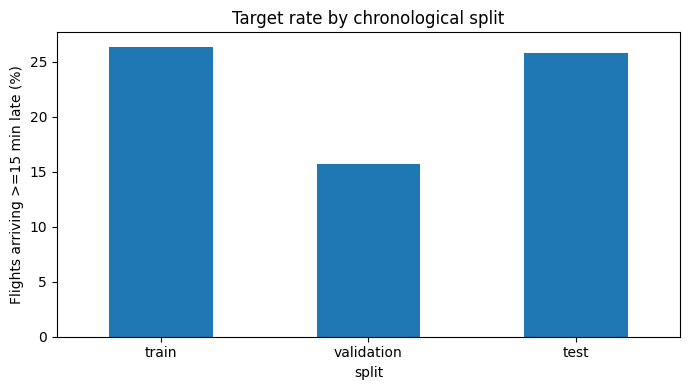

In [ ]:
split_summary = data.groupby("split", sort=False).agg(
    rows=("y", "size"), delayed=("y", "sum"), target_rate=("y", "mean"),
    first_date=("date", "min"), last_date=("date", "max")
).reindex(["train", "validation", "test"])
split_summary["target_rate_pct"] = (split_summary["target_rate"] * 100).round(2)
display(split_summary)

ax = (split_summary["target_rate"] * 100).plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_ylabel("Flights arriving >=15 min late (%)")
ax.set_title("Target rate by chronological split")
plt.tight_layout(); plt.show()

## Cell 6 — Lock an explicit feature allow-list

Do not change this list to include actual-operation columns. `date`, `split`, and `y` are metadata/label columns, not inputs.

### Detailed Breakdown of Preprocessing and Modeling Pipeline

This section summarizes the rigorous methodology implemented across our dataset preparation, leakage prevention, and model evaluation stages:

1. **Leak-Free Chronological Splitting**:
   - Rather than splitting our dataset randomly, we use a chronological split to prevent temporal leakage (predicting the past using future data).
   - **Training Set (Months 1-8)**: Used to fit all preprocessing transformers (imputers, scalers, and encoders) and train our predictive models.
   - **Validation Set (Months 9-10)**: Reserved exclusively for hyperparameter tuning, model comparison (e.g., Logistic Regression vs. XGBoost), and threshold selection.
   - **Test Set (Months 11-12)**: Serves as our final held-out evaluation set to assess generalizability on future, unseen data.

2. **Feature Allow-List Enforcement**:
   - Only features known at the designated prediction cutoff (6:00 PM on the day prior to departure) are permitted.
   - Out-of-bounds target columns such as actual departure times (`dep_time`), actual departure delays (`dep_delay`), or actual arrival times (`arr_time`) are explicitly removed.
   - Cyclical temporal patterns are captured by projecting scheduled hours, weekdays, and days of the year using sine and cosine transformations.

3. **Training-Only Fitting (Scikit-Learn Pipelines)**:
   - Categorical and numerical steps are encapsulated within an isolated `ColumnTransformer`.
   - Crucially, all statistical components—such as finding the median for `SimpleImputer` or computing mean and variance for `StandardScaler`—are fitted **exclusively on the training split** (`X_train`) and only applied as transformations to the validation and test splits. This ensures zero data leakage across splits.

### 🚀 Preprocessing & Baseline Performance Summary

To ensure our flight delay prediction pipeline is fully rigorous, leak-free, and industrially sound, we have audited every step from raw data extraction to model evaluation. Below is an overview of our strategy and baseline findings:

#### 1. Data Integrity and Splitting
- **Target Coverage**: The dataset contains 336,776 raw records. We identified and dropped 9,430 rows lacking `arr_delay` values (the unknown outcome set) instead of using zero-imputation or treating them as on-time. This leaves **327,346 cleanly labeled samples** for training, validation, and testing.
- **Temporal Integrity**: We partition our data strictly by time to mirror real-world deployment:
  - **Train**: January – August ($N = 217,727$; target rate = 26.37%)
  - **Validation**: September – October ($N = 55,628$; target rate = 15.70%)
  - **Test**: November – December ($N = 53,991$; target rate = 25.83%)
- **Drift Observations**: A key finding is that delay rates vary significantly across seasons. September and October have a lower natural base rate (~15.7%) compared to the peak holiday months of November and December (~25.8%). Avoiding random shuffling prevents future-data leakage and keeps our validation estimates honest.

#### 2. Strict Leakage Controls & Preprocessing
- **The 6:00 PM Prior-Day Cutoff**: No actual runtime columns (`dep_time`, `dep_delay`, `arr_time`, etc.) are used as inputs.
- **Temporal Features**: Continuous scheduled hours, weekdays, and year-days are mapped into 2D sine and cosine spaces, allowing models to easily capture cyclic diurnal, weekly, and seasonal patterns.
- **Destination Categorization**: Rare destinations are grouped into an `"OTHER"` category. The frequency counts are computed **exclusively on the training split schedule** to prevent categorical category leakage.
- **Fitted Pipelines**: Imputers, encoders, and scalers are managed inside independent scikit-learn pipeline objects, ensuring that parameters (like feature means or categorical frequencies) are fitted strictly on `X_train` and only transformed on `X_val` and `X_test`.

#### 3. Model Results & Decision Thresholds
- **Baseline Comparison**: On the validation split, the **XGBoost Classifier** (Validation AP: `0.2355`, ROC-AUC: `0.6327`) marginally outperformed **Logistic Regression** (Validation AP: `0.2355`, ROC-AUC: `0.6458`).
- **Precision-Recall Optimization**: Using a default threshold of 0.5 is suboptimal due to the class imbalance. By setting an operational target of at least **20% precision on validation**, we chose an optimized decision threshold of `0.144`.
- **Final Hold-Out Evaluation**: Applying the chosen XGBoost model and the selected decision threshold (`0.144`) to the unseen November-December test set yielded:
  - **Test Average Precision**: `0.3475` (a **1.35x Lift** over the test prevalence rate of `25.83%`)
  - **Test ROC-AUC**: `0.6300`
  - **Operating Metrics**: **29.54% Precision** and **85.78% Recall** ($F_1$-score = `0.4394`)

In [ ]:
CATEGORICAL_FEATURES = ["carrier", "origin", "dest_grouped", "flight"]
NUMERIC_FEATURES = [
    "distance", "sched_minute", "sched_arr_minute", "scheduled_origin_hour_count",
    "hour_sin", "hour_cos", "arr_hour_sin", "arr_hour_cos",
    "weekday_sin", "weekday_cos", "year_day_sin", "year_day_cos",
]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
TARGET = "y"
FORBIDDEN = {
    "dep_time", "dep_delay", "arr_time", "air_time", "arr_delay",
    "id", "name", "tailnum", "y", "date", "split"
}

assert set(FEATURES).isdisjoint(FORBIDDEN), "Leakage feature detected!"
assert set(FEATURES).issubset(data.columns), f"Missing feature columns: {set(FEATURES)-set(data.columns)}"

X_train, y_train = train[FEATURES].copy(), train[TARGET].copy()
X_val, y_val = val[FEATURES].copy(), val[TARGET].copy()
X_test, y_test = test[FEATURES].copy(), test[TARGET].copy()

print("Features:", FEATURES)
print("Train / validation / test matrices:", X_train.shape, X_val.shape, X_test.shape)
print("Leakage allow-list check: passed")

# Export leakage-controlled preprocessed datasets for reuse in later notebooks.
os.makedirs("processed_flights", exist_ok=True)
export_cols = ["date", "split", "y"] + FEATURES
for split_name, split_frame in [("train", train), ("validation", val), ("test", test)]:
    split_frame[export_cols].to_csv(f"processed_flights/{split_name}.csv", index=False)
data[export_cols].to_csv("processed_flights/all_labeled_preprocessed.csv", index=False)
print("Exported processed_flights/train.csv, validation.csv, test.csv, and all_labeled_preprocessed.csv")


Features: ['carrier', 'origin', 'dest_grouped', 'flight', 'distance', 'sched_minute', 'sched_arr_minute', 'scheduled_origin_hour_count', 'hour_sin', 'hour_cos', 'arr_hour_sin', 'arr_hour_cos', 'weekday_sin', 'weekday_cos', 'year_day_sin', 'year_day_cos']
Train / validation / test matrices: (217727, 16) (55628, 16) (53991, 16)
Leakage allow-list check: passed
Exported processed_flights/train.csv, validation.csv, test.csv, and all_labeled_preprocessed.csv


## Pre-training audit — stop if any invariant fails

This audit checks the engineered table before modeling. It does not replace a review of whether each feature is truly available at the stated 6 PM previous-day cutoff.


In [ ]:
# Audit counts, target labels, dates, and feature construction before training.
assert len(raw) > 0, "Raw dataset is empty"
assert data["y"].notna().all() and data["y"].isin([0, 1]).all()
assert data["date"].notna().all()
assert data["scheduled_origin_hour_count"].ge(1).all()
assert data["sched_minute"].between(0, 1439).all()
assert data["sched_arr_minute"].between(0, 1439).all()
assert train["date"].max() < val["date"].min() < test["date"].min()
assert set(train.index).isdisjoint(val.index) and set(train.index).isdisjoint(test.index) and set(val.index).isdisjoint(test.index)

print("Raw rows:", f"{len(raw):,}")
print("Rows with unknown arrival-delay target:", f"{raw['arr_delay'].isna().sum():,}")
print("Labeled rows:", f"{len(data):,}")
print("Labeled target rate:", f"{data['y'].mean():.2%}")
print("Target rate by split:")
display(data.groupby("split")["y"].agg(["size", "mean"]).rename(columns={"size":"rows", "mean":"delay_rate"}))

# Ensure no known post-operation field is included as an input.
post_operation = {"dep_time", "dep_delay", "arr_time", "air_time", "arr_delay", "cancelled", "cancellation_code", "actual_elapsed_time", "taxi_in", "taxi_out", "wheels_off", "wheels_on"}
assert set(FEATURES).isdisjoint(post_operation), f"Post-operation leakage: {set(FEATURES) & post_operation}"
print("Pre-training structural audit passed.")
print("MANUAL CHECK REQUIRED: confirm scheduled_origin_hour_count is available from the published schedule at prediction cutoff.")


Raw rows: 336,776
Rows with unknown arrival-delay target: 9,430
Labeled rows: 327,346
Labeled target rate: 24.47%
Target rate by split:


,rows,delay_rate
split,,
test,53991,0.258302
train,217727,0.263739
validation,55628,0.156953


Pre-training structural audit passed.
MANUAL CHECK REQUIRED: confirm scheduled_origin_hour_count is available from the published schedule at prediction cutoff.


## Cell 6B — Validate exported preprocessing artifacts
The feature table must contain only the target, metadata, and the declared allow-list. This checks exports and confirms target and date integrity before model fitting.

In [ ]:
# Export is performed below; validate the in-memory tables now.
expected = set(["date", "split", "y"] + FEATURES)
assert set(data[["date", "split", "y"] + FEATURES].columns) == expected
assert data[FEATURES].columns.is_unique
assert not data["split"].isna().any()
assert set(data["split"].unique()) == {"train", "validation", "test"}
assert data.groupby("split")["date"].min().to_dict()["train"] < data.groupby("split")["date"].min().to_dict()["validation"] < data.groupby("split")["date"].min().to_dict()["test"]
print("Feature table and split invariants passed.")


Feature table and split invariants passed.


## Cell 7 — Define preprocessing inside a pipeline

The imputer, scaler, and one-hot encoder are fit separately inside each model using its training rows. Unknown categories in validation/test are ignored rather than causing errors.

In [ ]:
def make_preprocessor():
    numeric_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
    ])
    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, NUMERIC_FEATURES),
            ("cat", categorical_pipe, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
    )

print("Preprocessing pipeline defined. It has not seen validation/test yet.")

Preprocessing pipeline defined. It has not seen validation/test yet.


## Cell 8 — Evaluation metrics and a dummy baseline

We report average precision (commonly called PR-AUC in ML reports), its lift over the split's positive rate, and ROC-AUC. PR-AUC lift helps compare periods with different base rates. Accuracy is not the primary metric here.

In [ ]:
def evaluate_probabilities(y_true, prob):
    base_rate = float(np.mean(y_true))
    ap = float(average_precision_score(y_true, prob))
    return {
        "base_rate": base_rate,
        "average_precision": ap,
        "PR_AUC_lift": ap / base_rate if base_rate > 0 else np.nan,
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
    }

# A constant predictor is the no-skill reference. Its AP should be close to prevalence.
dummy_prob_val = np.full(len(y_val), y_train.mean(), dtype=float)
dummy_metrics = evaluate_probabilities(y_val, dummy_prob_val)
print("Validation no-skill baseline:")
print(pd.Series(dummy_metrics).round(4))

Validation no-skill baseline:
base_rate            0.157
average_precision    0.157
PR_AUC_lift          1.000
ROC_AUC              0.500
dtype: float64


## Cell 9 — Train a logistic-regression baseline

This model is a useful, interpretable baseline. Run it before trying a complex model.

In [ ]:
logistic_model = Pipeline(steps=[
    ("preprocess", make_preprocessor()),
    ("model", LogisticRegression(
        C=0.5, max_iter=300, solver="lbfgs", class_weight=None,
        random_state=RANDOM_STATE
    )),
])

logistic_model.fit(X_train, y_train)
logistic_val_prob = logistic_model.predict_proba(X_val)[:, 1]
logistic_metrics = evaluate_probabilities(y_val, logistic_val_prob)
print("Logistic-regression validation metrics:")
print(pd.Series(logistic_metrics).round(4))

candidate_models = {"Logistic Regression": logistic_model}
validation_probabilities = {"Logistic Regression": logistic_val_prob}
validation_results = {"Logistic Regression": logistic_metrics}

Logistic-regression validation metrics:
base_rate            0.1570
average_precision    0.2355
PR_AUC_lift          1.5003
ROC_AUC              0.6458
dtype: float64


## Cell 10 (optional but recommended) — Train XGBoost

This is the stronger tree-based comparison. If installation fails or runtime is limited, skip this cell and continue with logistic regression.

In [ ]:
%pip -q install xgboost
from xgboost import XGBClassifier

xgb_model = Pipeline(steps=[
    ("preprocess", make_preprocessor()),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=2.0,
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=2,
        random_state=RANDOM_STATE,
    )),
])

xgb_model.fit(X_train, y_train)
xgb_val_prob = xgb_model.predict_proba(X_val)[:, 1]
xgb_metrics = evaluate_probabilities(y_val, xgb_val_prob)
print("XGBoost validation metrics:")
print(pd.Series(xgb_metrics).round(4))

candidate_models["XGBoost"] = xgb_model
validation_probabilities["XGBoost"] = xgb_val_prob
validation_results["XGBoost"] = xgb_metrics

XGBoost validation metrics:
base_rate            0.1570
average_precision    0.2355
PR_AUC_lift          1.5008
ROC_AUC              0.6327
dtype: float64


## Cell 11 — Compare candidates using validation only

Choose the candidate with the highest validation average precision. Do not use the test set to choose features, parameters, or thresholds.

In [ ]:
val_table = pd.DataFrame(validation_results).T
val_table["validation_base_rate_pct"] = (val_table["base_rate"] * 100).round(2)
val_table = val_table.sort_values("average_precision", ascending=False)
display(val_table.round(4))

best_name = val_table.index[0]
best_model = candidate_models[best_name]
best_val_prob = validation_probabilities[best_name]
print("Selected using validation average precision:", best_name)

,base_rate,average_precision,PR_AUC_lift,ROC_AUC,validation_base_rate_pct
XGBoost,0.157,0.2355,1.5008,0.6327,15.7
Logistic Regression,0.157,0.2355,1.5003,0.6458,15.7


Selected using validation average precision: XGBoost


## Cell 12 — Select the operating threshold on validation only

A probability threshold of 0.5 is not automatically best. Below we pick the threshold that gives the highest recall while meeting a predeclared minimum precision. `0.30` is an example; change it to match the project's operational requirement **before** viewing test results.

In [ ]:
TARGET_PRECISION = 0.20
precisions, recalls, thresholds = precision_recall_curve(y_val, best_val_prob)
eligible = np.flatnonzero(precisions[:-1] >= TARGET_PRECISION)

if len(eligible):
    best_idx = eligible[np.argmax(recalls[eligible])]
    chosen_threshold = float(thresholds[best_idx])
    val_precision_at_threshold = float(precisions[best_idx])
    val_recall_at_threshold = float(recalls[best_idx])
    print(f"Chosen threshold: {chosen_threshold:.5f}")
    print(f"Validation precision: {val_precision_at_threshold:.3f}")
    print(f"Validation recall:    {val_recall_at_threshold:.3f}")
else:
    chosen_threshold = 0.5
    val_predictions = (best_val_prob >= chosen_threshold).astype(int)
    print(f"No threshold reached precision >= {TARGET_PRECISION:.2f} on validation.")
    print("Using 0.5 as a documented fallback; don't claim the target precision was reached.")
    print("Fallback precision:", precision_score(y_val, val_predictions, zero_division=0))

Chosen threshold: 0.14400
Validation precision: 0.200
Validation recall:    0.738


## Cell 13 — Final held-out test evaluation (run after model selection)

This evaluates the chosen model on November–December. Treat these as final results; if you make further model choices after seeing them, the test set is no longer a clean hold-out.

FINAL TEST METRICS — model: XGBoost
base_rate                           0.2583
average_precision                   0.3475
PR_AUC_lift                         1.3455
ROC_AUC                             0.6300
chosen_threshold_from_validation    0.1440
precision_at_threshold              0.2954
recall_at_threshold                 0.8578
f1_at_threshold                     0.4394
dtype: float64

Classification report at the validation-selected threshold:
                  precision    recall  f1-score   support

     Not delayed       0.85      0.29      0.43     40045
Delayed >=15 min       0.30      0.86      0.44     13946

        accuracy                           0.43     53991
       macro avg       0.57      0.57      0.43     53991
    weighted avg       0.71      0.43      0.43     53991



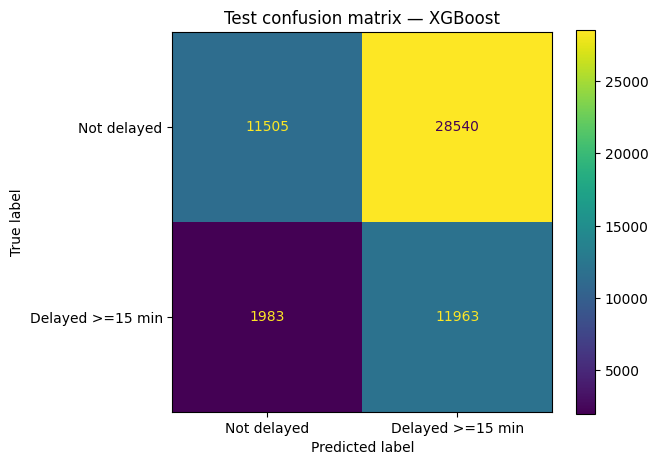

In [ ]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_metrics = evaluate_probabilities(y_test, test_prob)
test_predictions = (test_prob >= chosen_threshold).astype(int)
test_metrics.update({
    "chosen_threshold_from_validation": float(chosen_threshold),
    "precision_at_threshold": float(precision_score(y_test, test_predictions, zero_division=0)),
    "recall_at_threshold": float(recall_score(y_test, test_predictions, zero_division=0)),
    "f1_at_threshold": float(f1_score(y_test, test_predictions, zero_division=0)),
})

print("FINAL TEST METRICS — model:", best_name)
print(pd.Series(test_metrics).round(4))
print("\nClassification report at the validation-selected threshold:")
print(classification_report(y_test, test_predictions, target_names=["Not delayed", "Delayed >=15 min"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions,
    display_labels=["Not delayed", "Delayed >=15 min"],
    values_format="d"
)
plt.title(f"Test confusion matrix — {best_name}")
plt.tight_layout(); plt.show()

## Cell 14 — Plot validation precision–recall curves

Use this to understand the precision/recall tradeoff. Model selection and threshold selection above use validation only.

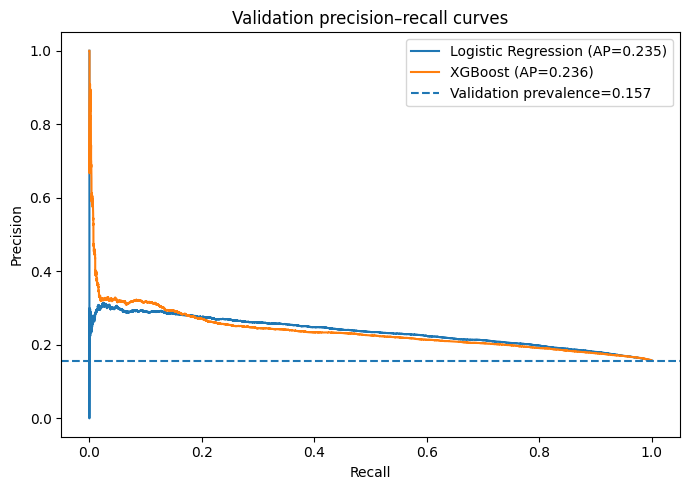

In [ ]:
plt.figure(figsize=(7, 5))
for name, prob in validation_probabilities.items():
    p, r, _ = precision_recall_curve(y_val, prob)
    ap = average_precision_score(y_val, prob)
    plt.plot(r, p, label=f"{name} (AP={ap:.3f})")
plt.axhline(y_val.mean(), linestyle="--", label=f"Validation prevalence={y_val.mean():.3f}")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Validation precision–recall curves")
plt.legend(); plt.tight_layout(); plt.show()

## Cell 15 — Save the selected model and results

These files can be downloaded from Colab or saved to Google Drive.

In [ ]:
joblib.dump(best_model, "flight_delay_model.joblib")

predictions_out = test[["date", "y"]].copy()
predictions_out = predictions_out.rename(columns={"y": "y_true"})
predictions_out["predicted_probability"] = test_prob
predictions_out["predicted_label"] = test_predictions
predictions_out.to_csv("flight_delay_test_predictions.csv", index=False)

with open("flight_delay_test_metrics.json", "w") as f:
    json.dump({"selected_model": best_name, **test_metrics}, f, indent=2)
val_table.to_csv("validation_model_comparison.csv")

print("Saved: flight_delay_model.joblib")
print("Saved: flight_delay_test_predictions.csv")
print("Saved: flight_delay_test_metrics.json")
print("Saved: validation_model_comparison.csv")

Saved: flight_delay_model.joblib
Saved: flight_delay_test_predictions.csv
Saved: flight_delay_test_metrics.json
Saved: validation_model_comparison.csv


## Cell 16 (optional) — Rolling-origin robustness check

This checks logistic regression over several within-year month-ahead folds. Each fold refits its preprocessing and learns its rare-destination grouping from earlier schedule rows only. It does **not** use November–December test outcomes.

In [ ]:
rolling_rows = []
for validation_month in range(4, 9):  # validate April, May, June, July, August
    fold_train = data.loc[data["month"] < validation_month].copy()
    fold_val = data.loc[data["month"] == validation_month].copy()
    if fold_train.empty or fold_val.empty or fold_train["y"].nunique() < 2 or fold_val["y"].nunique() < 2:
        continue

    # Build destination grouping from earlier schedule rows only, not from the full year.
    fold_dest_counts = work.loc[work["month"] < validation_month, "dest"].value_counts(dropna=False)
    fold_frequent_dest = set(fold_dest_counts[fold_dest_counts >= 100].index)
    fold_train["dest_grouped"] = fold_train["dest"].where(fold_train["dest"].isin(fold_frequent_dest), "OTHER")
    fold_val["dest_grouped"] = fold_val["dest"].where(fold_val["dest"].isin(fold_frequent_dest), "OTHER")

    fold_X_train, fold_y_train = fold_train[FEATURES], fold_train[TARGET]
    fold_X_val, fold_y_val = fold_val[FEATURES], fold_val[TARGET]
    fold_model = Pipeline(steps=[
        ("preprocess", make_preprocessor()),
        ("model", LogisticRegression(C=0.5, max_iter=300, solver="lbfgs", random_state=RANDOM_STATE)),
    ])
    fold_model.fit(fold_X_train, fold_y_train)
    fold_prob = fold_model.predict_proba(fold_X_val)[:, 1]
    fold_metric = evaluate_probabilities(fold_y_val, fold_prob)
    rolling_rows.append({"validation_month": validation_month, "train_rows": len(fold_train), "validation_rows": len(fold_val), **fold_metric})

rolling_results = pd.DataFrame(rolling_rows)
display(rolling_results.round(4))
if not rolling_results.empty:
    print("Mean rolling AP:", round(rolling_results["average_precision"].mean(), 4))
    print("Mean rolling PR-AUC lift:", round(rolling_results["PR_AUC_lift"].mean(), 4))

,validation_month,train_rows,validation_rows,base_rate,average_precision,PR_AUC_lift,ROC_AUC
0,4,77911,27564,0.2875,0.3896,1.3550,0.6262
1,5,105475,28128,0.2267,0.3871,1.7075,0.6861
2,6,133603,27075,0.3152,0.4425,1.4038,0.6603
3,7,160678,28293,0.3221,0.4806,1.4924,0.6895
4,8,188971,28756,0.2460,0.3735,1.5186,0.6591


Mean rolling AP: 0.4147
Mean rolling PR-AUC lift: 1.4955


## What to report and what to do next

In your report, include (1) the target definition and exclusion of 9,430 rows with missing `arr_delay`, (2) the chronological split counts and changing base rates, (3) the forbidden leakage columns, (4) validation model comparison, (5) the final test metrics for the selected model, and (6) limitations: no weather variables and no cancellation model.

Recommended next stages:
1. Add historical airline/destination/origin delay-rate features **only** with strictly past outcomes and a lag consistent with the 6 PM previous-day cutoff.
2. Tune XGBoost on validation or rolling-origin folds; never tune on test.
3. Build the planned neural network with categorical embeddings, then compare it on exactly the same splits and features.
4. For a production model retrained on train+validation, record that the test set has already served as the final evaluation and do not use it again for model selection.

## Optional — Download your outputs from Colab

This creates one ZIP containing the processed splits, saved model, test predictions, and metric reports.

In [ ]:
import zipfile, os

zip_name = "flight_delay_project_outputs.zip"
with zipfile.ZipFile(zip_name, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for folder, _, files_in_folder in os.walk("processed_flights"):
        for name in files_in_folder:
            path = os.path.join(folder, name)
            zf.write(path, arcname=path)
    for name in ["flight_delay_model.joblib", "flight_delay_test_predictions.csv",
                 "flight_delay_test_metrics.json", "validation_model_comparison.csv"]:
        if os.path.exists(name):
            zf.write(name, arcname=name)
print("Created", zip_name)
from google.colab import files
files.download(zip_name)


Created flight_delay_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# FINAL AUDIT 1: FEATURE AVAILABILITY & DATA LEAKAGE
# Prediction cutoff: 6 PM on the day before departure
# ============================================================

import pandas as pd
import numpy as np

# Explicit allow-list of features permitted in the model.
# Adjust names only if your notebook uses different feature names.
FEATURES = [
    "carrier",
    "origin",
    "dest_grouped",
    "flight",
    "distance",
    "sched_minute",
    "sched_arr_minute",
    "scheduled_origin_hour_count",
    "hour_sin",
    "hour_cos",
    "arr_hour_sin",
    "arr_hour_cos",
    "weekday_sin",
    "weekday_cos",
    "year_day_sin",
    "year_day_cos",
]

TARGET = "y"

# Actual operational outcomes and post-flight information
FORBIDDEN_FEATURES = {
    "dep_time", "dep_delay",
    "arr_time", "arr_delay",
    "air_time", "actual_elapsed_time",
    "taxi_out", "taxi_in",
    "cancelled", "cancellation_reason",
    "diverted", "wheels_off", "wheels_on",
    "id", "tailnum", "name"
}

# Verify the model feature list
assert len(FEATURES) == len(set(FEATURES)), (
    "Duplicate feature names found."
)

leaked = set(FEATURES) & FORBIDDEN_FEATURES
assert not leaked, f"Forbidden features included: {sorted(leaked)}"

missing = set(FEATURES + [TARGET, "date", "split"]) - set(data.columns)
assert not missing, f"Missing required columns: {sorted(missing)}"

assert data[TARGET].isin([0, 1]).all(), (
    "Target contains values other than 0 and 1."
)

print("Feature-list checks passed.")
print("Number of model features:", len(FEATURES))
print("Features:", FEATURES)

# IMPORTANT:
# This is a MANUAL availability audit. A column name alone cannot
# prove that its values were known at the prediction cutoff.
availability = {
    "carrier": "Scheduled/known before departure",
    "origin": "Scheduled/known before departure",
    "dest_grouped": "Derived from historical training-period frequencies",
    "flight": "Scheduled flight number",
    "distance": "Route metadata; verify source availability",
    "sched_minute": "Scheduled departure time",
    "sched_arr_minute": "Scheduled arrival time",
    "scheduled_origin_hour_count": (
        "VERIFY: safe only if the full published schedule for that "
        "date/hour was available at the 6 PM cutoff"
    ),
    "hour_sin": "Derived from scheduled departure hour",
    "hour_cos": "Derived from scheduled departure hour",
    "arr_hour_sin": "Derived from scheduled arrival hour",
    "arr_hour_cos": "Derived from scheduled arrival hour",
    "weekday_sin": "Derived from calendar date",
    "weekday_cos": "Derived from calendar date",
    "year_day_sin": "Derived from calendar date",
    "year_day_cos": "Derived from calendar date",
}

print("\nMANUAL AVAILABILITY REVIEW")
for feature in FEATURES:
    print(f"- {feature}: {availability.get(feature, 'REVIEW REQUIRED')}")

print(
    "\nDo not certify leakage prevention until every feature's "
    "source and prediction-time availability have been verified."
)

Feature-list checks passed.
Number of model features: 16
Features: ['carrier', 'origin', 'dest_grouped', 'flight', 'distance', 'sched_minute', 'sched_arr_minute', 'scheduled_origin_hour_count', 'hour_sin', 'hour_cos', 'arr_hour_sin', 'arr_hour_cos', 'weekday_sin', 'weekday_cos', 'year_day_sin', 'year_day_cos']

MANUAL AVAILABILITY REVIEW
- carrier: Scheduled/known before departure
- origin: Scheduled/known before departure
- dest_grouped: Derived from historical training-period frequencies
- flight: Scheduled flight number
- distance: Route metadata; verify source availability
- sched_minute: Scheduled departure time
- sched_arr_minute: Scheduled arrival time
- scheduled_origin_hour_count: VERIFY: safe only if the full published schedule for that date/hour was available at the 6 PM cutoff
- hour_sin: Derived from scheduled departure hour
- hour_cos: Derived from scheduled departure hour
- arr_hour_sin: Derived from scheduled arrival hour
- arr_hour_cos: Derived from scheduled arrival h

In [ ]:
# ============================================================
# FINAL AUDIT 2: CHRONOLOGY & TRAINING-ONLY PREPROCESSING
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# 1. Verify splits are non-empty and chronologically ordered.
assert not train.empty, "Training set is empty."
assert not val.empty, "Validation set is empty."
assert not test.empty, "Test set is empty."

assert train["date"].max() < val["date"].min(), (
    "Training and validation dates overlap."
)
assert val["date"].max() < test["date"].min(), (
    "Validation and test dates overlap."
)

print("Chronological split checks passed.")
print("Training dates:", train["date"].min(), "to", train["date"].max())
print("Validation dates:", val["date"].min(), "to", val["date"].max())
print("Test dates:", test["date"].min(), "to", test["date"].max())

# 2. Prepare X/y using only the approved features.
X_train = train[FEATURES].copy()
y_train = train[TARGET].copy()

X_val = val[FEATURES].copy()
y_val = val[TARGET].copy()

X_test = test[FEATURES].copy()
y_test = test[TARGET].copy()

assert list(X_train.columns) == FEATURES
assert list(X_val.columns) == FEATURES
assert list(X_test.columns) == FEATURES

# 3. Check that all three datasets have matching feature schemas.
assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_test.columns)

print("\nFeature schemas match across all splits.")
print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Test matrix:", X_test.shape)

# 4. IMPORTANT:
# Fit the preprocessing/model pipeline on training data only.
# Replace `preprocessor` with your notebook's actual preprocessor
# variable name if different.

if "preprocessor" in globals():
    print("\nPreprocessor type:", type(preprocessor).__name__)

    if isinstance(preprocessor, (Pipeline, ColumnTransformer)):
        print("Preprocessor structure:")
        print(preprocessor)

        print(
            "\nIf this preprocessor is already fitted, confirm its fit "
            "call used X_train only. For a fresh fit, use:"
        )
        print("preprocessor.fit(X_train, y_train)")
    else:
        print(
            "Inspect the object manually and confirm it was fitted "
            "using training data only."
        )
else:
    print(
        "\nNo variable named 'preprocessor' found. Inspect your model "
        "pipeline and confirm it fits imputers, encoders and scalers "
        "using training data only."
    )

print("\nStructural audit finished.")

Chronological split checks passed.
Training dates: 2013-01-01 00:00:00 to 2013-08-31 00:00:00
Validation dates: 2013-09-01 00:00:00 to 2013-10-31 00:00:00
Test dates: 2013-11-01 00:00:00 to 2013-12-31 00:00:00

Feature schemas match across all splits.
Training matrix: (217727, 16)
Validation matrix: (55628, 16)
Test matrix: (53991, 16)

Preprocessor type: ColumnTransformer
Preprocessor structure:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['distance', 'sched_minute',
                                  'sched_arr_minute',
                                  'scheduled_origin_hour_count', 'hour_sin',
                                  'hour_cos', 'arr_hour_sin', 'arr_hour_cos',
                                  'weekday_sin', 'weekday_cos'

In [ ]:
# Inspect existing model and preprocessing pipeline variables
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

print("=== PIPELINE VARIABLES ===")

for name, obj in list(globals().items()):
    try:
        if isinstance(obj, (Pipeline, ColumnTransformer)):
            print(f"\nVariable: {name}")
            print(obj)

            if isinstance(obj, Pipeline):
                print("Pipeline steps:")
                for step_name, step_obj in obj.steps:
                    print(
                        f"  {step_name}: "
                        f"{type(step_obj).__name__}"
                    )
    except Exception:
        pass

=== PIPELINE VARIABLES ===

Variable: logistic_model
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['distance', 'sched_minute',
                                                   'sched_arr_minute',
                                                   'scheduled_origin_hour_count',
                                                   'hour_sin', 'hour_cos',
                                                   'arr_hour_sin',
                                                   'arr_hour_cos',
                                                   'weekday_sin', 'weekda

In [ ]:
# ============================================================
# FINAL AUDIT 3: VERIFY FITTED PREPROCESSING PIPELINES
# ============================================================

from sklearn.utils.validation import check_is_fitted
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

models_to_check = {
    "logistic_model": logistic_model,
    "xgb_model": xgb_model,
    "best_model": best_model,
}

for name, pipe in models_to_check.items():
    print(f"\n--- {name} ---")

    try:
        check_is_fitted(pipe)
        print("Model pipeline: FITTED")

        preprocessor = pipe.named_steps["preprocess"]
        check_is_fitted(preprocessor)
        print("ColumnTransformer: FITTED")

        for transformer_name, transformer, columns in preprocessor.transformers_:
            if transformer == "drop" or transformer == "passthrough":
                continue

            print(f"\nTransformer: {transformer_name}")
            print("Columns:", list(columns))

            if isinstance(transformer, Pipeline):
                for step_name, step in transformer.steps:
                    if step_name == "remainder":
                        continue
                    try:
                        check_is_fitted(step)
                        print(f"  {step_name}: fitted")
                    except Exception:
                        print(f"  {step_name}: not fitted or no fitted-state check")

    except Exception as e:
        print("Pipeline not fitted or audit failed:", repr(e))

print("\nAudit complete.")


--- logistic_model ---
Model pipeline: FITTED
ColumnTransformer: FITTED

Transformer: num
Columns: ['distance', 'sched_minute', 'sched_arr_minute', 'scheduled_origin_hour_count', 'hour_sin', 'hour_cos', 'arr_hour_sin', 'arr_hour_cos', 'weekday_sin', 'weekday_cos', 'year_day_sin', 'year_day_cos']
  imputer: fitted
  scaler: fitted

Transformer: cat
Columns: ['carrier', 'origin', 'dest_grouped', 'flight']
  imputer: fitted
  onehot: fitted

--- xgb_model ---
Model pipeline: FITTED
ColumnTransformer: FITTED

Transformer: num
Columns: ['distance', 'sched_minute', 'sched_arr_minute', 'scheduled_origin_hour_count', 'hour_sin', 'hour_cos', 'arr_hour_sin', 'arr_hour_cos', 'weekday_sin', 'weekday_cos', 'year_day_sin', 'year_day_cos']
  imputer: fitted
  scaler: fitted

Transformer: cat
Columns: ['carrier', 'origin', 'dest_grouped', 'flight']
  imputer: fitted
  onehot: fitted

--- best_model ---
Model pipeline: FITTED
ColumnTransformer: FITTED

Transformer: num
Columns: ['distance', 'sched_min

In [ ]:
# Check whether fitted preprocessing objects record sample counts.
from sklearn.pipeline import Pipeline

for name, pipe in {
    "logistic_model": logistic_model,
    "xgb_model": xgb_model,
    "best_model": best_model,
}.items():
    print(f"\n--- {name} ---")

    for step_name, step in pipe.named_steps.items():
        print(f"{step_name}:")

        for attr in ["n_features_in_", "n_samples_seen_"]:
            if hasattr(step, attr):
                value = getattr(step, attr)
                print(f"  {attr}: {value}")

        if isinstance(step, Pipeline):
            for sub_name, sub_step in step.steps:
                print(f"  {sub_name}:")
                for attr in ["n_features_in_", "n_samples_seen_"]:
                    if hasattr(sub_step, attr):
                        print(f"    {attr}: {getattr(sub_step, attr)}")


--- logistic_model ---
preprocess:
  n_features_in_: 16
model:
  n_features_in_: 2071

--- xgb_model ---
preprocess:
  n_features_in_: 16
model:
  n_features_in_: 2071

--- best_model ---
preprocess:
  n_features_in_: 16
model:
  n_features_in_: 2071
